In [14]:
# First, let's try to read the file and check its content
try:
    # Try comma as delimiter first
    df = pd.read_csv("1030.csv", header=None, encoding="cp932", delimiter=',', na_filter=False)
except:
    try:
        # Try tab as delimiter if comma fails
        df = pd.read_csv("1030.csv", header=None, encoding="cp932", delimiter='\t', na_filter=False)
    except:
        # If both fail, try with the most flexible settings
        df = pd.read_csv("1030.csv", header=None, encoding="cp932", delimiter=None, engine='python', na_filter=False)

# Display the first few rows to check the structure
print("File structure:")
print(df)




File structure:
                                    0
0            測定日時,2025-10-31 01:10:07
1                               コメント,
2                                測定者,
3                       測定方式,,吸光度,１波長
4                        測定法,,エンドポイント
5                         プレート,,96ウェル
6                        波長,,λ1:450nm
7                            レスポンス,,1
8                            測定方向,,↓↓
9                                 吸光度
10        ,1,2,3,4,5,6,7,8,9,10,11,12
11  A,1.133,2.561,0.549,0.257,,,,,,,,
12  B,0.836,1.924,0.814,0.126,,,,,,,,
13  C,0.785,1.079,0.937,0.179,,,,,,,,
14  D,0.482,1.349,0.874,0.103,,,,,,,,
15  E,0.537,0.937,0.149,0.550,,,,,,,,
16  F,0.454,0.595,0.156,0.502,,,,,,,,
17  G,0.452,0.313,0.162,0.707,,,,,,,,
18  H,0.174,0.192,0.053,0.832,,,,,,,,


In [32]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

# 日本語フォント設定（Windows）
rcParams['font.family'] = 'Meiryo'  # または 'MS Gothic'
import pandas as pd

# すでに df は読み込めている前提（df.shape[1] == 1 の場合が今回の状況）
# もしまだなら参考: df = pd.read_csv("1030.csv", header=None, encoding="cp932", engine="python")

# 1) 1列しかない場合は、カンマで分割して複数列に展開
if df.shape[1] == 1:
    df2 = df[0].astype(str).str.split(",", expand=True)
else:
    df2 = df.copy()

# 2) 前処理：前後空白の除去
df2 = df2.map(lambda x: x.strip() if isinstance(x, str) else x)

# 3) プレート開始行（先頭列が A〜H の最初の行）を検出
mask_ah = df2[0].isin(list("ABCDEFGH"))
if not mask_ah.any():
    # 先頭列が「A〜H」になっていない場合、念のため全角・半角や空白の影響をさらに除去
    df2[0] = df2[0].astype(str).str.replace(r"\s+", "", regex=True)
    mask_ah = df2[0].isin(list("ABCDEFGH"))

if not mask_ah.any():
    raise ValueError("A〜H 行で始まるプレートデータを検出できませんでした。ヘッダの書式をご確認ください。")

start_row = mask_ah.idxmax()  # 最初に True になった行

# 4) A〜H（8行）× 列1〜4 を抽出（A〜H の 8 行分を切り出す）
plate = df2.iloc[start_row:start_row+8, 1:5].copy()

# 5) 数値化（空文字や非数は NaN に）
# 5) 数値化（空文字や非数は NaN に）
# 文字列の前後空白除去は列単位で処理（applymapの代替）
plate = plate.apply(lambda col: col.str.strip() if col.dtype == object else col)
plate = plate.apply(pd.to_numeric, errors="coerce")

# 6) 行名・列名を整える
plate.index = list("ABCDEFGH")
plate.columns = range(1, 5)
print("Plate data:")
print(plate)


Plate data:
       1      2      3      4
A  1.133  2.561  0.549  0.257
B  0.836  1.924  0.814  0.126
C  0.785  1.079  0.937  0.179
D  0.482  1.349  0.874  0.103
E  0.537  0.937  0.149  0.550
F  0.454  0.595  0.156  0.502
G  0.452  0.313  0.162  0.707
H  0.174  0.192  0.053  0.832


【標準曲線（対数軸・線形モデル + ブランク補正）】
ブランク(H行 OD): 0.1830
OD_corrected = 0.747375 * log10(conc) + -1.537766


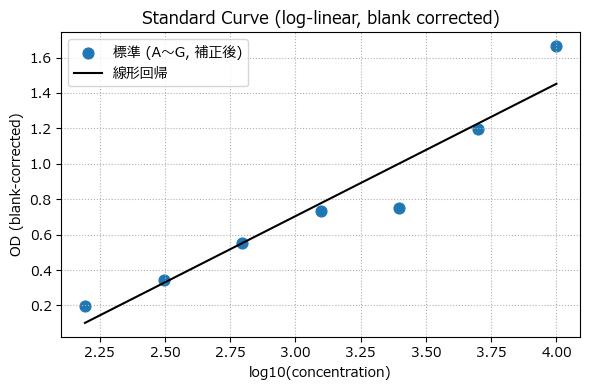


【各ウェルの濃度（ng/mL）】
             3           4
A   352.591329  143.407076
B   797.712151    0.000000
C  1165.258645    0.000000
D   959.681769    0.000000
E     0.000000  353.679302
F     0.000000  305.059683
G     0.000000  573.691425
H     0.000000  843.199846

【列平均】
   mean_concentration(ng/mL)
3                 409.405487
4                 277.379667

[保存完了] unknown_concentrations_by_well.csv / unknown_concentrations_summary.csv


In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ───────── 標準設定 ─────────
std_cols = [1, 2]  # 1,2列が標準
std_conc_full = np.array([10000, 5000, 2500, 1250, 625, 312.5, 156.25, 0])

# 標準 OD（平均）
std_values_full = plate[std_cols].mean(axis=1).values

# ブランク = H行
blank = std_values_full[-1]
std_corrected_full = std_values_full - blank

# A〜G（Hは除外）
std_conc = std_conc_full[:-1]
std_corrected = std_corrected_full[:-1]

# log10変換
log_conc = np.log10(std_conc)

# ───────── 線形回帰（sklearnなし）─────────
# y = a*x + b
# a = Cov(x,y)/Var(x)
a = np.cov(log_conc, std_corrected, bias=True)[0,1] / np.var(log_conc)
b = np.mean(std_corrected) - a * np.mean(log_conc)

print("【標準曲線（対数軸・線形モデル + ブランク補正）】")
print(f"ブランク(H行 OD): {blank:.4f}")
print(f"OD_corrected = {a:.6f} * log10(conc) + {b:.6f}")

# ───────── 図示 ─────────
xfit = np.linspace(log_conc.min(), log_conc.max(), 200)
yfit = a * xfit + b

plt.figure(figsize=(6,4))
plt.scatter(log_conc, std_corrected, label="標準 (A〜G, 補正後)", s=60)
plt.plot(xfit, yfit, color="black", label="線形回帰")
plt.xlabel("log10(concentration)")
plt.ylabel("OD (blank-corrected)")
plt.title("Standard Curve (log-linear, blank corrected)")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

# ───────── 逆変換 → 濃度計算 ─────────
def od_to_conc(od_raw):
    od_corr = od_raw - blank
    if np.isnan(od_corr):
        return np.nan
    if od_corr <= 0:
        return 0.0
    logc = (od_corr - b) / a
    return 10 ** logc

# 未知サンプル 3・4列目
sample_cols = [3, 4]
conc_table = pd.DataFrame(index=plate.index, columns=sample_cols, dtype=float)

for c in sample_cols:
    conc_table[c] = plate[c].apply(od_to_conc)

# 列平均
conc_summary = conc_table.mean(axis=0).to_frame(name="mean_concentration(ng/mL)")

print("\n【各ウェルの濃度（ng/mL）】")
print(conc_table)
print("\n【列平均】")
print(conc_summary)

# 保存
conc_table.to_csv("unknown_concentrations_by_well.csv", encoding="utf-8-sig")
conc_summary.to_csv("unknown_concentrations_summary.csv", encoding="utf-8-sig")
print("\n[保存完了] unknown_concentrations_by_well.csv / unknown_concentrations_summary.csv")


【標準曲線（2列のみ／対数軸・線形／ブランク補正）: 単位 pg/mL】
blank(H, 0 pg/mL): 0.1920
OD_corrected = 1.132303 * log10(conc_pg_per_mL) + -2.447497  (R^2 = 0.8994)


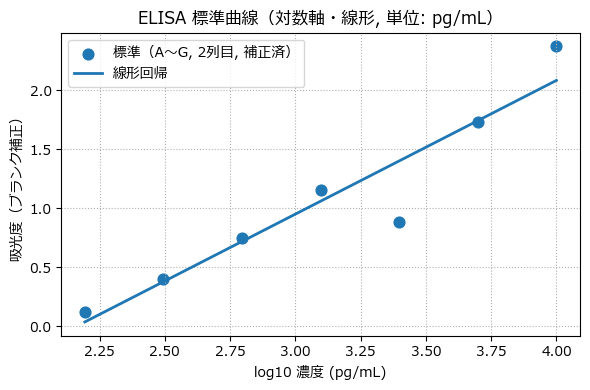


【各ウェルの推定濃度（原血清換算, pg/mL）】
   conc_pg_per_mL_serum
A            899.351914
B           1541.579675
C           1979.676150
D           1741.627725

【サマリー（原血清換算, pg/mL）】
      sample  n_reps  mean_serum_pg_per_mL  sd_serum_pg_per_mL  \
0  pregnant1       2           1220.465794          454.123605   
1  pregnant2       2           1860.651937          168.325656   

   min_serum_pg_per_mL  max_serum_pg_per_mL  
0           899.351914          1541.579675  
1          1741.627725          1979.676150  

[保存] col3_concentrations_by_well_pg.csv / pregnant_summary_pg.csv


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ========= 設定（単位はすべて pg/mL）=========
STD_COL = 2         # スタンダードは2列目のみを使用
SAMPLE_COL = 3       # 未知サンプルは3列目
DILUTION_FACTOR = 3  # 3倍希釈 → 原血清は×3

# 標準濃度系列（A=10000 pg/mL → 2倍希釈 → G=156.25, H=0）
std_conc_full = np.array([10000, 5000, 2500, 1250, 625, 312.5, 156.25, 0.0], dtype=float)

# 日本語フォント（必要に応じて）
plt.rcParams["font.family"] = "Meiryo"   # Windows想定。環境に応じて変更可
plt.rcParams["axes.unicode_minus"] = False

# ========= 標準抽出・ブランク補正 =========
# 2列目の A〜H の生OD
std_values_full = plate[STD_COL].values.astype(float)

# H行（0 pg/mL）のODをブランクとして減算
blank = std_values_full[-1]
std_corr_full = std_values_full - blank

# 回帰は A〜G（ゼロは対数不可のため除外）
std_conc = std_conc_full[:-1]       # A..G
std_corr = std_corr_full[:-1]       # A..G

# 対数軸・線形回帰（numpyのみ）
# y = a * log10(conc) + b
logc = np.log10(std_conc)
a = np.cov(logc, std_corr, bias=True)[0, 1] / np.var(logc)
b = np.mean(std_corr) - a * np.mean(logc)

# 参考: 決定係数
r = np.corrcoef(logc, std_corr)[0, 1]
r2 = r ** 2

print("【標準曲線（2列のみ／対数軸・線形／ブランク補正）: 単位 pg/mL】")
print(f"blank(H, 0 pg/mL): {blank:.4f}")
print(f"OD_corrected = {a:.6f} * log10(conc_pg_per_mL) + {b:.6f}  (R^2 = {r2:.4f})")

# 可視化（確認用）
xfit = np.linspace(logc.min(), logc.max(), 200)
yfit = a * xfit + b
plt.figure(figsize=(6, 4))
plt.scatter(logc, std_corr, label="標準（A〜G, 2列目, 補正済）", s=60)
plt.plot(xfit, yfit, label="線形回帰", linewidth=2)
plt.xlabel("log10 濃度 (pg/mL)")
plt.ylabel("吸光度（ブランク補正）")
plt.title("ELISA 標準曲線（対数軸・線形, 単位: pg/mL）")
plt.grid(True, linestyle=":")
plt.legend()
plt.tight_layout()
plt.show()

# ========= 逆変換（OD → 濃度 [pg/mL]）=========
def od_to_conc_pg_per_mL(od_raw: float) -> float:
    """生OD → ブランク補正 → 濃度推定（pg/mL）。
       補正後OD<=0 は 0 とみなす。NaN は NaN を返す。"""
    if pd.isna(od_raw):
        return np.nan
    od_corr = od_raw - blank
    if od_corr <= 0:
        return 0.0
    log_conc = (od_corr - b) / a
    return 10 ** log_conc

# ========= 未知サンプル（3列）=========
# pregnant1: A–B（duplicate）
# pregnant2: C–D（duplicate）
conc_by_well = plate[[SAMPLE_COL]].copy()
conc_by_well.columns = ["OD_raw"]

# 希釈後の推定濃度（pg/mL）
conc_by_well["conc_pg_per_mL_measured"] = conc_by_well["OD_raw"].apply(od_to_conc_pg_per_mL)
# 原血清濃度（希釈倍率で補正）
conc_by_well["conc_pg_per_mL_serum"] = conc_by_well["conc_pg_per_mL_measured"] * DILUTION_FACTOR

# 複製の抽出
pregnant1_wells = ["A", "B"]
pregnant2_wells = ["C", "D"]

preg1_vals = conc_by_well.loc[pregnant1_wells, "conc_pg_per_mL_serum"]
preg2_vals = conc_by_well.loc[pregnant2_wells, "conc_pg_per_mL_serum"]

summary = pd.DataFrame({
    "sample": ["pregnant1", "pregnant2"],
    "n_reps": [preg1_vals.count(), preg2_vals.count()],
    "mean_serum_pg_per_mL": [preg1_vals.mean(), preg2_vals.mean()],
    "sd_serum_pg_per_mL": [preg1_vals.std(ddof=1), preg2_vals.std(ddof=1)],
    "min_serum_pg_per_mL": [preg1_vals.min(), preg2_vals.min()],
    "max_serum_pg_per_mL": [preg1_vals.max(), preg2_vals.max()],
})

print("\n【各ウェルの推定濃度（原血清換算, pg/mL）】")
print(conc_by_well.loc[pregnant1_wells + pregnant2_wells, ["conc_pg_per_mL_serum"]])

print("\n【サマリー（原血清換算, pg/mL）】")
print(summary)

# 保存
conc_by_well.to_csv("col3_concentrations_by_well_pg.csv", encoding="utf-8-sig")
summary.to_csv("pregnant_summary_pg.csv", index=False, encoding="utf-8-sig")
print("\n[保存] col3_concentrations_by_well_pg.csv / pregnant_summary_pg.csv")


In [34]:
# ========= 妊娠群（3列）: A–B=pregnant1, C–D=pregnant2（3倍希釈あり） =========
SAMPLE_COL = 3
DILUTION_FACTOR_PREG = 3.0  # 妊娠群のみ3倍補正

conc_by_well = plate[[SAMPLE_COL]].copy()
conc_by_well.columns = ["OD_raw"]

# 希釈後の推定濃度（pg/mL）
conc_by_well["conc_pg_per_mL_measured"] = conc_by_well["OD_raw"].apply(od_to_conc_pg_per_mL)
# 原血清濃度（妊娠群のみ ×3）
conc_by_well["conc_pg_per_mL_serum"] = conc_by_well["conc_pg_per_mL_measured"] * DILUTION_FACTOR_PREG

pregnant1_wells = ["A", "B"]
pregnant2_wells = ["C", "D"]

preg1_vals = conc_by_well.loc[pregnant1_wells, "conc_pg_per_mL_serum"]
preg2_vals = conc_by_well.loc[pregnant2_wells, "conc_pg_per_mL_serum"]

summary = pd.DataFrame({
    "sample": ["pregnant1", "pregnant2"],
    "n_reps": [preg1_vals.count(), preg2_vals.count()],
    "mean_serum_pg_per_mL": [preg1_vals.mean(), preg2_vals.mean()],
    "sd_serum_pg_per_mL": [preg1_vals.std(ddof=1), preg2_vals.std(ddof=1)],
    "min_serum_pg_per_mL": [preg1_vals.min(), preg2_vals.min()],
    "max_serum_pg_per_mL": [preg1_vals.max(), preg2_vals.max()],
})

print("\n【妊娠群（原血清換算, pg/mL）】")
print(summary)
conc_by_well.to_csv("col3_concentrations_by_well_preg_pg.csv", encoding="utf-8-sig")
summary.to_csv("pregnant_summary_pg.csv", index=False, encoding="utf-8-sig")
print("[保存] col3_concentrations_by_well_preg_pg.csv / pregnant_summary_pg.csv")


# ========= 雄（male）: 3列 E–H（原血清をアプライ → 希釈補正なし） =========
male_wells = ["E", "F", "G", "H"]
male_od = plate.loc[male_wells, SAMPLE_COL]           # 3列のE–H
male_conc_measured = male_od.apply(od_to_conc_pg_per_mL)  # そのまま原血清
male_conc = male_conc_measured.to_frame(name="male_serum_pg_per_mL")

print("\n【雄 個体別 原血清濃度 (pg/mL)】")
print(male_conc)
male_conc.to_csv("male_individual_serum_pg_per_mL.csv", encoding="utf-8-sig")
print("[保存] male_individual_serum_pg_per_mL.csv")


# ========= 雌（female）: 4列 A–D（原血清をアプライ → 希釈補正なし） =========
FEMALE_COL = 4
female_wells = ["A", "B", "C", "D"]
female_od = plate.loc[female_wells, FEMALE_COL]            # 4列のA–D
female_conc_measured = female_od.apply(od_to_conc_pg_per_mL)  # そのまま原血清
female_conc = female_conc_measured.to_frame(name="female_serum_pg_per_mL")

print("\n【雌 個体別 原血清濃度 (pg/mL)】")
print(female_conc)
female_conc.to_csv("female_individual_serum_pg_per_mL.csv", encoding="utf-8-sig")
print("[保存] female_individual_serum_pg_per_mL.csv")



【妊娠群（原血清換算, pg/mL）】
      sample  n_reps  mean_serum_pg_per_mL  sd_serum_pg_per_mL  \
0  pregnant1       2           1220.465794          454.123605   
1  pregnant2       2           1860.651937          168.325656   

   min_serum_pg_per_mL  max_serum_pg_per_mL  
0           899.351914          1541.579675  
1          1741.627725          1979.676150  
[保存] col3_concentrations_by_well_preg_pg.csv / pregnant_summary_pg.csv

【雄 個体別 原血清濃度 (pg/mL)】
   male_serum_pg_per_mL
E                   0.0
F                   0.0
G                   0.0
H                   0.0
[保存] male_individual_serum_pg_per_mL.csv

【雌 個体別 原血清濃度 (pg/mL)】
   female_serum_pg_per_mL
A              165.549124
B                0.000000
C                0.000000
D                0.000000
[保存] female_individual_serum_pg_per_mL.csv


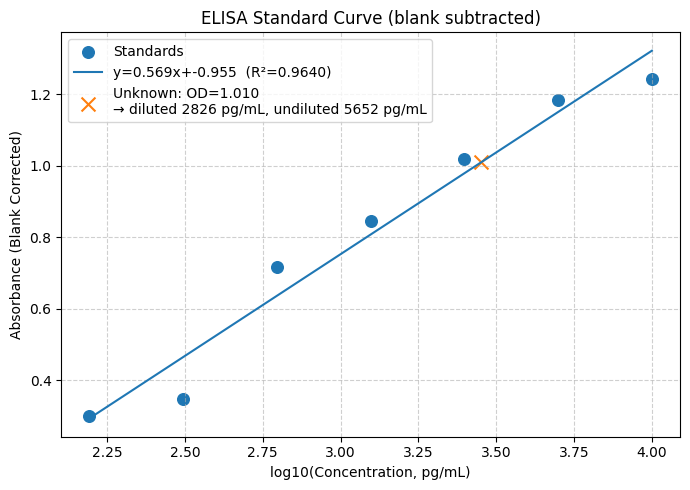

回帰式: y = 0.569 * log10(conc) + -0.955
R² = 0.9640
未知試料: 平均OD=1.010
  希釈状態の推定濃度 = 2826.1 pg/mL
  原血清換算（×2）= 5652.2 pg/mL


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ==== データ入力 ====
data = {
    "Conc_ng": [10000, 5000, 2500, 1250, 625, 312, 156, 0],
    "OD1": [1.533, 1.604, 1.466, 0.969, 0.978, 0.394, 0.335, 0.024],
    "OD2": [0.952, 0.768, 0.572, 0.725, 0.455, 0.302, 0.268, -0.023]
}
df = pd.DataFrame(data)

# ==== 平均とブランク補正 ====
df["OD_mean"] = df[["OD1", "OD2"]].mean(axis=1)
blank = df.loc[df["Conc_ng"] == 0, "OD_mean"].values[0]
df["OD_corrected"] = df["OD_mean"] - blank

# ==== 回帰分析（log10濃度 vs ブランク補正後OD）====
df_nonblank = df[df["Conc_ng"] > 0]
x = np.log10(df_nonblank["Conc_ng"])
y = df_nonblank["OD_corrected"]
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

# ==== 吸光度→濃度 変換関数（希釈補正付き）====
def absorbance_to_conc(od, slope=slope, intercept=intercept, blank=blank, dilution_factor=1.0):
    """
    od: 未知試料の吸光度（ブランク未補正の平均OD）
    dilution_factor: 実試料に対する希釈倍率（2倍希釈なら2）
    戻り値: 原血清（未希釈）換算の濃度 ng/mL
    """
    corrected = od - blank
    log_conc = (corrected - intercept) / slope
    conc_diluted = 10 ** log_conc
    return conc_diluted * dilution_factor

# ==== 未知試料例（2倍希釈）====
unknown_OD = (1.141 + 0.88) / 2  # あなたの値
dilution_factor = 2
conc_undiluted = absorbance_to_conc(unknown_OD, dilution_factor=dilution_factor)

# 参考：グラフ上の点は「希釈状態での濃度」に対応するので、表示用に別途計算
def absorbance_to_conc_diluted_only(od, slope=slope, intercept=intercept, blank=blank):
    corrected = od - blank
    return 10 ** ((corrected - intercept) / slope)

conc_diluted = absorbance_to_conc_diluted_only(unknown_OD)

# ==== 検量線のプロット ====
plt.figure(figsize=(7,5))
# スタンダード点
plt.scatter(np.log10(df_nonblank["Conc_ng"]), df_nonblank["OD_corrected"], label='Standards', s=70)

# 回帰直線
x_fit = np.linspace(np.log10(156), np.log10(10000), 200)
plt.plot(x_fit, slope * x_fit + intercept,
         label=f'y={slope:.3f}x+{intercept:.3f}  (R²={r_value**2:.4f})')

# 未知試料（希釈状態の位置を×印で表示）
plt.scatter(np.log10(conc_diluted), unknown_OD - blank, marker='x', s=100,
            label=f'Unknown: OD={unknown_OD:.3f}\n→ diluted {conc_diluted:.0f} pg/mL, undiluted {conc_undiluted:.0f} pg/mL')

plt.xlabel("log10(Concentration, pg/mL)")
plt.ylabel("Absorbance (Blank Corrected)")
plt.title("ELISA Standard Curve (blank subtracted)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

print(f"回帰式: y = {slope:.3f} * log10(conc) + {intercept:.3f}")
print(f"R² = {r_value**2:.4f}")
print(f"未知試料: 平均OD={unknown_OD:.3f}")
print(f"  希釈状態の推定濃度 = {conc_diluted:.1f} pg/mL")
print(f"  原血清換算（×{dilution_factor}）= {conc_undiluted:.1f} pg/mL")


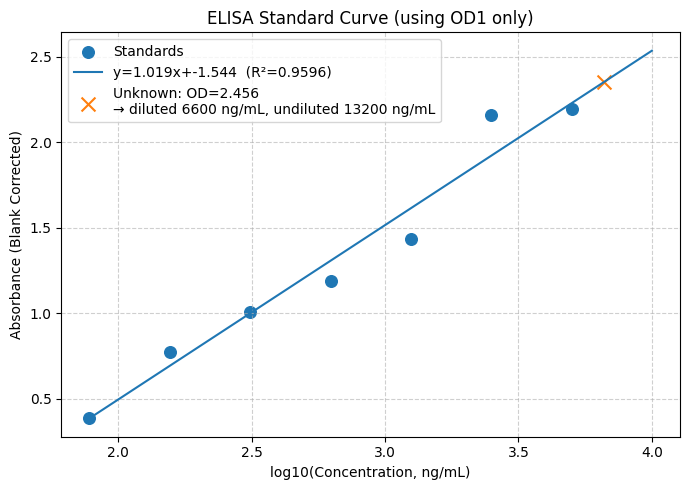

回帰式: y = 1.019 * log10(conc) + -1.544
R² = 0.9596
未知試料: 平均OD=2.456
  希釈状態の推定濃度 = 6600.2 ng/mL
  原血清換算（×2）= 13200.3 ng/mL


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ==== データ入力 ====
data = {
    "Conc_ng": [5000, 2500, 1250, 625, 312, 156, 78, 0],
    "OD1": [2.297, 2.264, 1.538, 1.296, 1.115, 0.880, 0.495, 0.106],
}
df = pd.DataFrame(data)

# ==== ブランク補正 ====
blank = df.loc[df["Conc_ng"] == 0, "OD1"].values[0]
df["OD_corrected"] = df["OD1"] - blank

# ==== 回帰分析（log10濃度 vs ブランク補正後OD）====
df_nonblank = df[df["Conc_ng"] > 0]
x = np.log10(df_nonblank["Conc_ng"])
y = df_nonblank["OD_corrected"]
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

# ==== 吸光度→濃度 変換関数（希釈補正付き）====
def absorbance_to_conc(od, slope=slope, intercept=intercept, blank=blank, dilution_factor=1.0):
    corrected = od - blank
    log_conc = (corrected - intercept) / slope
    conc_diluted = 10 ** log_conc
    return conc_diluted * dilution_factor

# ==== 未知試料（例：2倍希釈）====
unknown_OD = (2.456+2.818)/2
dilution_factor = 2
conc_undiluted = absorbance_to_conc(unknown_OD, dilution_factor=dilution_factor)

# 検量線上での希釈状態の濃度
conc_diluted = 10 ** ((unknown_OD - blank - intercept) / slope)

# ==== 検量線プロット ====
plt.figure(figsize=(7,5))
plt.scatter(np.log10(df_nonblank["Conc_ng"]), df_nonblank["OD_corrected"], label='Standards', s=70)

x_fit = np.linspace(np.log10(78), np.log10(10000), 200)
plt.plot(x_fit, slope * x_fit + intercept, label=f'y={slope:.3f}x+{intercept:.3f}  (R²={r_value**2:.4f})')

plt.scatter(np.log10(conc_diluted), unknown_OD - blank, marker='x', s=100,
            label=f'Unknown: OD={unknown_OD:.3f}\n→ diluted {conc_diluted:.0f} ng/mL, undiluted {conc_undiluted:.0f} ng/mL')

plt.xlabel("log10(Concentration, ng/mL)")
plt.ylabel("Absorbance (Blank Corrected)")
plt.title("ELISA Standard Curve (using OD1 only)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# ==== 出力 ====
print(f"回帰式: y = {slope:.3f} * log10(conc) + {intercept:.3f}")
print(f"R² = {r_value**2:.4f}")
print(f"未知試料: 平均OD={unknown_OD:.3f}")
print(f"  希釈状態の推定濃度 = {conc_diluted:.1f} ng/mL")
print(f"  原血清換算（×{dilution_factor}）= {conc_undiluted:.1f} ng/mL")

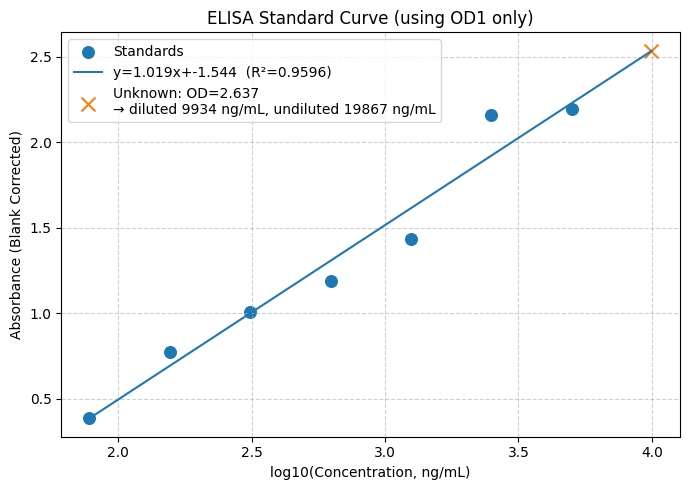

回帰式: y = 1.019 * log10(conc) + -1.544
R² = 0.9596
未知試料: 平均OD=2.637
  希釈状態の推定濃度 = 9933.6 ng/mL
  原血清換算（×2）= 19867.2 ng/mL


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# ==== データ入力 ====
data = {
    "Conc_ng": [5000, 2500, 1250, 625, 312, 156, 78, 0],
    "OD1": [2.297, 2.264, 1.538, 1.296, 1.115, 0.880, 0.495, 0.106],
}
df = pd.DataFrame(data)

# ==== ブランク補正 ====
blank = df.loc[df["Conc_ng"] == 0, "OD1"].values[0]
df["OD_corrected"] = df["OD1"] - blank

# ==== 回帰分析（log10濃度 vs ブランク補正後OD）====
df_nonblank = df[df["Conc_ng"] > 0]
x = np.log10(df_nonblank["Conc_ng"])
y = df_nonblank["OD_corrected"]
slope, intercept, r_value, p_value, std_err = stats.linregress(x, y)

# ==== 吸光度→濃度 変換関数（希釈補正付き）====
def absorbance_to_conc(od, slope=slope, intercept=intercept, blank=blank, dilution_factor=1.0):
    corrected = od - blank
    log_conc = (corrected - intercept) / slope
    conc_diluted = 10 ** log_conc
    return conc_diluted * dilution_factor

# ==== 未知試料（例：2倍希釈）====
unknown_OD = (2.456+2.818)/2
dilution_factor = 2
conc_undiluted = absorbance_to_conc(unknown_OD, dilution_factor=dilution_factor)

# 検量線上での希釈状態の濃度
conc_diluted = 10 ** ((unknown_OD - blank - intercept) / slope)

# ==== 検量線プロット ====
plt.figure(figsize=(7,5))
plt.scatter(np.log10(df_nonblank["Conc_ng"]), df_nonblank["OD_corrected"], label='Standards', s=70)

x_fit = np.linspace(np.log10(78), np.log10(10000), 200)
plt.plot(x_fit, slope * x_fit + intercept, label=f'y={slope:.3f}x+{intercept:.3f}  (R²={r_value**2:.4f})')

plt.scatter(np.log10(conc_diluted), unknown_OD - blank, marker='x', s=100,
            label=f'Unknown: OD={unknown_OD:.3f}\n→ diluted {conc_diluted:.0f} ng/mL, undiluted {conc_undiluted:.0f} ng/mL')

plt.xlabel("log10(Concentration, ng/mL)")
plt.ylabel("Absorbance (Blank Corrected)")
plt.title("ELISA Standard Curve (using OD1 only)")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# ==== 出力 ====
print(f"回帰式: y = {slope:.3f} * log10(conc) + {intercept:.3f}")
print(f"R² = {r_value**2:.4f}")
print(f"未知試料: 平均OD={unknown_OD:.3f}")
print(f"  希釈状態の推定濃度 = {conc_diluted:.1f} ng/mL")
print(f"  原血清換算（×{dilution_factor}）= {conc_undiluted:.1f} ng/mL")